# Model 1: Bitcoin price forecasting with ARIMA

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

Bitcoin is traded every day of the year and its price in dollars is public, so the question "how much will a bitcoin cost tomorrow" is asked by everyone who holds one. The assistant of the project should be able to answer it with a number and a range. The question this notebook answers is whether the past of the price contains enough information to forecast its next days, and how good that forecast is compared with the simplest possible answer, which is that tomorrow the price will be the same as today.

The dataset is the bitcoin price prediction file published on Kaggle by team-ai. It has one row per day from April 28, 2013 to July 31, 2017 with the opening, highest, lowest and closing price in dollars, the traded volume and the market capitalisation, and a second file with the following seven days, August 1 to 7, 2017, that serves as a final unseen week.

The technique is ARIMA, the time series model taught in week thirteen. Unlike the regressions of the other models it has no predictors other than the past of the series itself: an ARIMA(p, d, q) differences the series d times until it has no trend, then explains each value with its p previous values and its q previous errors. Before it can be fitted the series has to be made stationary, meaning that its mean and its spread stop changing over time, and the notebook spends its first half checking that with the tools of the course, the decomposition, the augmented Dickey-Fuller test and the autocorrelation plots.

### Libraries

In [1]:
# Dataset handling
import os
import warnings
import kagglehub
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Time series tools
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Evaluation and persistence
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib

%matplotlib inline
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

/home/jony/ai-project/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Understanding (CRISP-DM 2)

The dataset is downloaded through kagglehub, which caches it locally and returns the folder, so the cell works unchanged on a local machine and in Google Colab. Both files are loaded, the training history and the final week.

In [2]:
path = kagglehub.dataset_download('team-ai/bitcoin-price-prediction')
print('Path to dataset files:', path)
print(os.listdir(path))

bitcoin = pd.read_csv(os.path.join(path, 'bitcoin_price_Training - Training.csv'))
bitcoin_week = pd.read_csv(os.path.join(path, 'bitcoin_price_1week_Test - Test.csv'))
bitcoin.head()

Path to dataset files: /home/jony/.cache/kagglehub/datasets/team-ai/bitcoin-price-prediction/versions/2
['bitcoin_price_Training - Training.csv', 'bitcoin_price_1week_Test - Test.csv']


,Date,Open,High,Low,Close,Volume,Market Cap
0,"Jul 31, 2017",2763.24,2889.62,2720.61,2875.34,"860,575,000","45,535,800,000"
1,"Jul 30, 2017",2724.39,2758.53,2644.85,2757.18,"705,943,000","44,890,700,000"
2,"Jul 29, 2017",2807.02,2808.76,2692.80,2726.45,"803,746,000","46,246,700,000"
3,"Jul 28, 2017",2679.73,2897.45,2679.73,2809.01,"1,380,100,000","44,144,400,000"
4,"Jul 27, 2017",2538.71,2693.32,2529.34,2671.78,"789,104,000","41,816,500,000"


Each row is one day, and the file is sorted newest first: the first row is July 31, 2017 with a closing price of 2,875 dollars. `Date` is text in the form "Jul 31, 2017", the four prices are numbers, and `Volume` and `Market Cap` are text with thousands separators, so they cannot be used as numbers yet. The target of the notebook is `Close`, the price at the end of the day.

In [3]:
print("Rows and columns:", bitcoin.shape)
bitcoin.info()
print()
print("Days with no volume recorded:", int((bitcoin['Volume'] == '-').sum()))

Rows and columns: (1556, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1556 entries, 0 to 1555
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date        1556 non-null   str    
 1   Open        1556 non-null   float64
 2   High        1556 non-null   float64
 3   Low         1556 non-null   float64
 4   Close       1556 non-null   float64
 5   Volume      1556 non-null   str    
 6   Market Cap  1556 non-null   str    
dtypes: float64(4), str(3)
memory usage: 85.2 KB

Days with no volume recorded: 243


There are 1,556 days and 7 columns with no missing value in the price columns, but 243 days have a dash instead of a volume, all of them at the start of the history when exchanges did not report it. The volume is not used by an ARIMA, which reads only the price, so those dashes are turned into missing values and left alone.

In [4]:
# Parse the dates, sort oldest first and give the table a daily index
def prepare(frame):
    frame = frame.copy()
    frame['Date'] = pd.to_datetime(frame['Date'])
    frame = frame.sort_values('Date').set_index('Date').asfreq('D')
    for column in ['Volume', 'Market Cap']:
        frame[column] = pd.to_numeric(frame[column].str.replace(',', ''), errors='coerce')
    return frame

bitcoin = prepare(bitcoin)
bitcoin_week = prepare(bitcoin_week)

print("First day:", bitcoin.index.min().date(), " last day:", bitcoin.index.max().date())
print("Days in the index:", len(bitcoin), " missing closing prices:", int(bitcoin['Close'].isna().sum()))
print("Final week:", bitcoin_week.index.min().date(), "to", bitcoin_week.index.max().date())
bitcoin.describe().round(2)

First day: 2013-04-28  last day: 2017-07-31
Days in the index: 1556  missing closing prices: 0
Final week: 2017-08-01 to 2017-08-07


,Open,High,Low,Close,Volume,Market Cap
count,1556.00,1556.00,1556.00,1556.00,1.313000e+03,1.556000e+03
mean,582.63,597.99,567.85,584.24,1.481643e+08,8.694353e+09
std,523.14,542.99,505.88,525.90,3.242987e+08,8.707288e+09
min,68.50,74.56,65.53,68.43,2.857830e+06,7.792550e+08
25%,254.29,260.33,248.84,254.32,2.071070e+07,3.598355e+09
50%,438.60,447.56,430.57,438.86,4.530140e+07,6.386210e+09
75%,662.44,674.52,646.74,663.40,9.037880e+07,9.898830e+09
max,2953.22,2999.91,2840.53,2958.11,2.569530e+09,4.839120e+10


After sorting, the history runs from April 28, 2013 to July 31, 2017, 1,556 consecutive days with no gap, which `asfreq('D')` confirms since it would have inserted empty rows otherwise. The final week runs from August 1 to 7, 2017. The closing price has a mean of 584 dollars but a median of 439 and a maximum of 2,958, so most of the history sits below 700 dollars and the last months are far above it, which is the trend the plot below shows. The volume has 1,313 values because of the 243 early dashes.

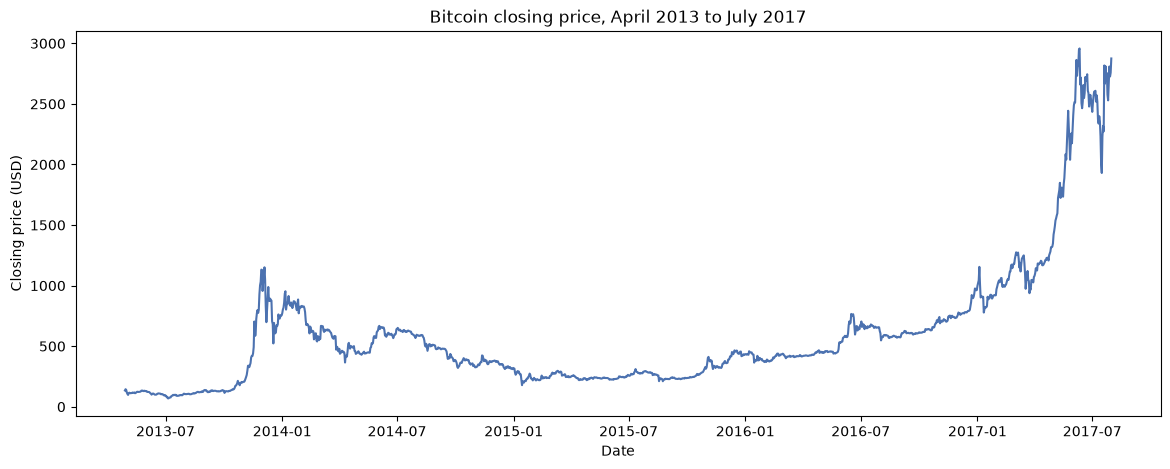

Date
2013-12-31     754.01
2014-12-31     320.19
2015-12-31     430.57
2016-12-31     963.74
2017-12-31    2875.34
Freq: YE-DEC, Name: Close, dtype: float64


In [5]:
TARGET = 'Close'
plt.figure(figsize=(14, 5))
plt.plot(bitcoin.index, bitcoin[TARGET], color='#4c72b0')
plt.title('Bitcoin closing price, April 2013 to July 2017')
plt.xlabel('Date')
plt.ylabel('Closing price (USD)')
plt.show()
print(bitcoin[TARGET].resample('YE').last().round(2))

The line is the closing price of every day. It starts at 134 dollars, spikes to 1,000 in late 2013, falls through 2014 to about 200, moves sideways through 2015 and then climbs steeply through 2016 and 2017 to close the history at 2,875. The year-end values printed under the plot give the same picture: 754, 320, 431, 964 and finally 2,875 in July 2017. Two things about this shape matter for the model. The mean of the series is clearly not constant, so it is not stationary as it stands. And the swings grow with the level: a 10 percent move in 2015 was 20 dollars and in 2017 it is 250, so the spread grows with the price, which is what the course calls a multiplicative series and treats with a logarithm.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The exploration follows the order of the course: decompose the series to see its components, test whether it is stationary, transform it until it is, and read the autocorrelation plots of the transformed series to choose the order of the model.

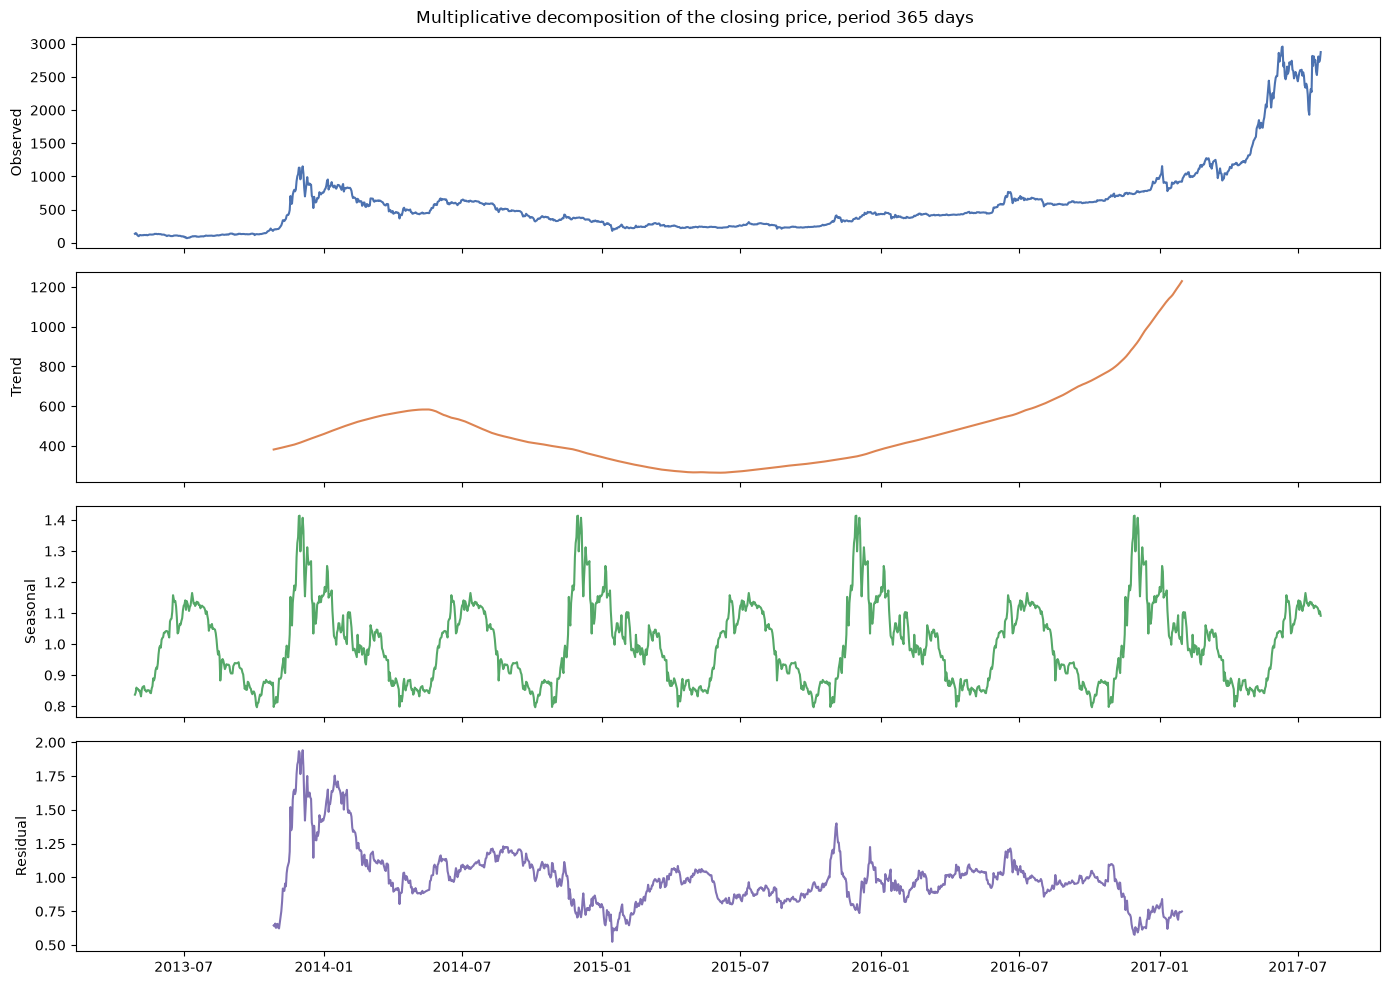

Range of the seasonal factor: 0.796 to 1.414


In [6]:
# Decomposition into trend, seasonal pattern and residual, with a yearly period
DAYS_PER_YEAR = 365
decomposition = seasonal_decompose(bitcoin[TARGET], model='multiplicative', period=DAYS_PER_YEAR)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(decomposition.observed, color='#4c72b0')
axes[0].set_ylabel('Observed')
axes[1].plot(decomposition.trend, color='#dd8452')
axes[1].set_ylabel('Trend')
axes[2].plot(decomposition.seasonal, color='#55a868')
axes[2].set_ylabel('Seasonal')
axes[3].plot(decomposition.resid, color='#8172b3')
axes[3].set_ylabel('Residual')
plt.suptitle('Multiplicative decomposition of the closing price, period 365 days')
plt.tight_layout()
plt.show()
print("Range of the seasonal factor:", round(decomposition.seasonal.min(), 3), "to", round(decomposition.seasonal.max(), 3))

The decomposition splits the series into three parts that multiply back into the original. The trend panel is the slow movement, obtained by averaging over a year on each side, so it loses half a year at each end. The seasonal panel is the pattern that repeats every 365 days, and the residual panel is what neither of the other two explains. The multiplicative form was chosen because the swings grow with the level.

The trend panel shows the fall of 2014 and the rise from 2016 without the daily noise. The seasonal factor runs from 0.80 to 1.41, so the yearly pattern multiplies the price by up to 40 percent above or 20 percent below the trend, and with only four years of history that pattern is fitted on four repetitions and should not be trusted much: the peak of December 2013 and the rise of the spring of 2017 are enough to create a "seasonality" that is mostly two events. The residual is not flat noise, it is wider in 2013 and 2017 than in 2015, which is the same growing spread the raw plot showed. The conclusion is that the series has a strong trend, a weak and doubtful seasonal pattern, and a spread tied to its level. An ARIMA without a seasonal part, on the logarithm of the price, is the fit for that.

In [7]:
# Augmented Dickey-Fuller test: the null hypothesis is that the series is not
# stationary, and a p-value at or below 0.05 rejects it
SIGNIFICANCE = 0.05

def adf_report(series, name):
    statistic, p_value, lags, observations, _, _ = adfuller(series.dropna())
    verdict = 'stationary' if p_value <= SIGNIFICANCE else 'not stationary'
    print("%-28s ADF statistic %8.3f   p-value %.2e   lags %2d   observations %d   -> %s"
          % (name, statistic, p_value, lags, observations, verdict))

adf_report(bitcoin[TARGET], 'Closing price')
adf_report(np.log(bitcoin[TARGET]), 'Log of closing price')
adf_report(bitcoin[TARGET].diff(), 'First difference')
adf_report(np.log(bitcoin[TARGET]).diff(), 'First difference of the log')

Closing price                ADF statistic    2.536   p-value 9.99e-01   lags 24   observations 1531   -> not stationary
Log of closing price         ADF statistic   -0.790   p-value 8.22e-01   lags 23   observations 1532   -> not stationary
First difference             ADF statistic   -7.634   p-value 1.97e-11   lags 23   observations 1531   -> stationary
First difference of the log  ADF statistic   -7.285   p-value 1.47e-10   lags 22   observations 1532   -> stationary


The augmented Dickey-Fuller test is the formal check of stationarity. Its null hypothesis is that the series drags a trend that never fades, so a p-value is the probability of seeing a series like this one if it were not stationary, and a value at or below 0.05 rejects that and declares the series stationary. This is one of the places where a p-value decides something, because the eye cannot tell a slow trend from a stationary series with long swings.

The raw price gives a statistic of 2.5 and a p-value of 0.999, as far from stationary as a series can be. Its logarithm does not help on its own, with a p-value of 0.82, because the logarithm fixes the growing spread but not the trend. One difference does: the first difference of the price gives a statistic of -7.6 and the first difference of the logarithm -7.3, both with p-values near zero. So the series needs one differencing, d equals 1, and the logarithm is kept because of the spread. The first difference of the logarithm is the daily return, the percentage change from one day to the next, which is the series the model actually reads.

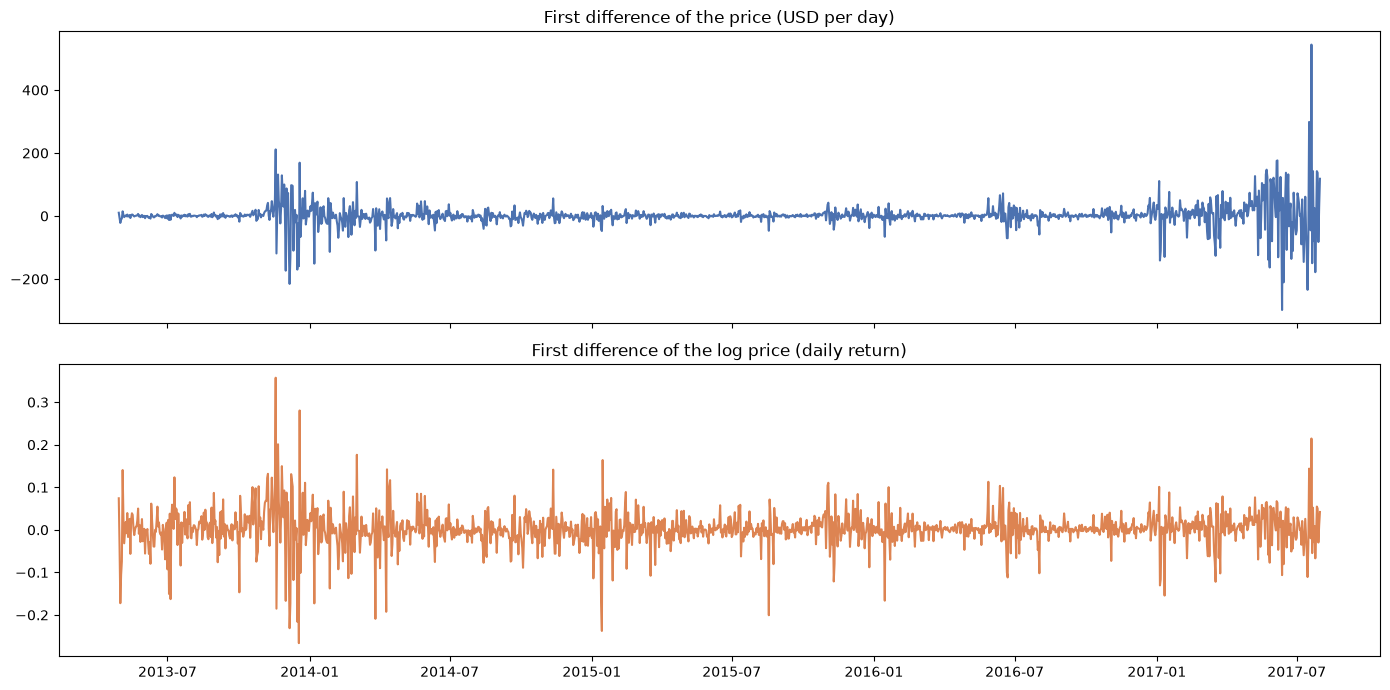

Spread of the price difference, first year vs last year: 38.2 vs 63.7 dollars
Spread of the log return, first year vs last year: 0.064 vs 0.035


In [8]:
# The series the model reads: daily log returns
log_price = np.log(bitcoin[TARGET])
log_return = log_price.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(bitcoin[TARGET].diff(), color='#4c72b0')
axes[0].set_title('First difference of the price (USD per day)')
axes[1].plot(log_return, color='#dd8452')
axes[1].set_title('First difference of the log price (daily return)')
plt.tight_layout()
plt.show()
print("Spread of the price difference, first year vs last year: %.1f vs %.1f dollars"
      % (bitcoin[TARGET].diff().head(DAYS_PER_YEAR).std(), bitcoin[TARGET].diff().tail(DAYS_PER_YEAR).std()))
print("Spread of the log return, first year vs last year: %.3f vs %.3f"
      % (log_return.head(DAYS_PER_YEAR).std(), log_return.tail(DAYS_PER_YEAR).std()))

Both panels oscillate around zero, which is what removing the trend does, but they differ in how the spread behaves. In the top panel, the difference in dollars, the swings are small until 2016 and then explode in 2017, and the printed spreads confirm it: 38 dollars in the first year against 64 in the last. In the bottom panel, the daily return, the spread is 0.064 in the first year and 0.035 in the last, so the swings did not grow with the price, they actually shrank as the market matured. The logarithm turned a series whose spread depended on its level into one whose spread is stable, which is the condition ARIMA needs and the reason the model is fitted on the log price.

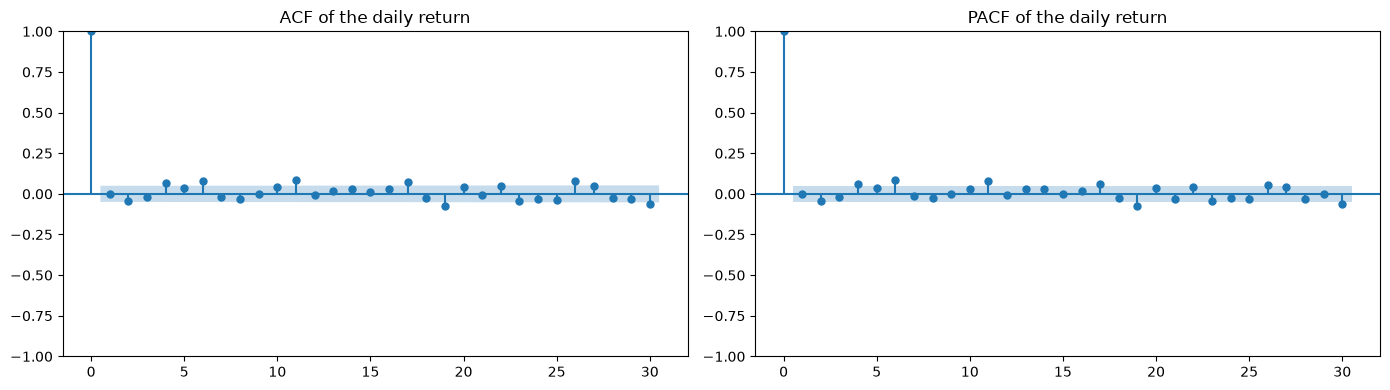

Confidence band around zero: +/- 0.050
ACF at lags 1 to 6:  [-0.001 -0.043 -0.019  0.064  0.039  0.077]
PACF at lags 1 to 6: [-0.001 -0.043 -0.019  0.063  0.038  0.084]


In [9]:
# Autocorrelation and partial autocorrelation of the daily return
LAGS = 30
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(log_return, lags=LAGS, ax=axes[0])
axes[0].set_title('ACF of the daily return')
plot_pacf(log_return, lags=LAGS, ax=axes[1], method='ywm')
axes[1].set_title('PACF of the daily return')
plt.tight_layout()
plt.show()

confidence_band = 1.96 / np.sqrt(len(log_return))
print("Confidence band around zero: +/- %.3f" % confidence_band)
print("ACF at lags 1 to 6: ", np.round(sm.tsa.acf(log_return, nlags=6)[1:], 3))
print("PACF at lags 1 to 6:", np.round(sm.tsa.pacf(log_return, nlags=6)[1:], 3))

The ACF measures how much the return of a day resembles the return k days earlier, one bar per lag, and the PACF measures the same after discounting the days in between. The shaded band marks where a bar is indistinguishable from zero, here plus or minus 0.050, and a bar that crosses it is a real correlation. In the course's reading, the number of bars that cross in the PACF suggests p and the number in the ACF suggests q.

Almost nothing crosses. The first three lags are -0.001, -0.043 and -0.019 in both plots, all inside the band, and in thirty lags only lag 6 pokes out at 0.077 in the ACF and 0.084 in the PACF, barely past the edge, which with thirty bars is about what chance produces. This is the picture of a series with no memory: today's return tells almost nothing about tomorrow's, which is the definition of a random walk and what financial theory predicts for a liquid market. The plots suggest p equals 0 and q equals 0, that is, that the best forecast of the log price is the last log price. The grid search in the next section checks that suggestion by AIC and the evaluation checks it against real days.

## Machine Learning Model (CRISP-DM 4: Modeling)

The last 30 days of the history are held back as a validation stretch, the model is fitted on the days before, and the order is chosen by AIC. The course does this with `auto_arima` from the pmdarima package, which is not installed in this environment and is not installed here either. The same search is done by hand instead: every combination of p from 0 to 3 and q from 0 to 3, with d fixed at 1 as the Dickey-Fuller test decided, is fitted and its AIC printed. AIC rewards fit and charges for every parameter, so the lowest value wins and two values within a couple of units are tied.

In [10]:
# Split the history without shuffling: the last 30 days are the validation stretch
VALIDATION_DAYS = 30
log_train = log_price.iloc[:-VALIDATION_DAYS]
price_validation = bitcoin[TARGET].iloc[-VALIDATION_DAYS:]
print("Training days:", len(log_train), " from", log_train.index.min().date(), "to", log_train.index.max().date())
print("Validation days:", len(price_validation), " from", price_validation.index.min().date(), "to", price_validation.index.max().date())

Training days: 1526  from 2013-04-28 to 2017-07-01
Validation days: 30  from 2017-07-02 to 2017-07-31


In [11]:
# Manual grid over the order, d fixed at 1, ranked by AIC
MAX_P, D, MAX_Q = 3, 1, 3
grid = []
for p in range(MAX_P + 1):
    for q in range(MAX_Q + 1):
        fitted = ARIMA(log_train, order=(p, D, q)).fit()
        grid.append({'order': (p, D, q), 'AIC': fitted.aic, 'BIC': fitted.bic})
grid = pd.DataFrame(grid).sort_values('AIC').reset_index(drop=True)
print(grid.round(1).to_string())
BEST_ORDER = grid.loc[0, 'order']
print()
print("Order with the lowest AIC:", BEST_ORDER)

        order     AIC     BIC
0   (3, 1, 3) -5339.3 -5302.0
1   (3, 1, 2) -5338.6 -5306.6
2   (2, 1, 3) -5337.8 -5305.8
3   (1, 1, 3) -5337.1 -5310.4
4   (0, 1, 0) -5329.7 -5324.4
5   (2, 1, 2) -5328.5 -5301.8
6   (2, 1, 0) -5328.4 -5312.5
7   (3, 1, 1) -5328.4 -5301.8
8   (0, 1, 2) -5328.1 -5312.1
9   (1, 1, 0) -5327.7 -5317.1
10  (0, 1, 1) -5327.7 -5317.1
11  (3, 1, 0) -5327.0 -5305.7
12  (2, 1, 1) -5326.6 -5305.3
13  (0, 1, 3) -5326.5 -5305.1
14  (1, 1, 2) -5326.2 -5304.8
15  (1, 1, 1) -5325.8 -5309.8

Order with the lowest AIC: (3, 1, 3)


The table ranks the sixteen candidates. The lowest AIC is (3, 1, 3) at -5339, but the next three orders are within two units of it and the plain random walk (0, 1, 0), with no parameter at all, sits at -5330, ten units behind. Ten units of AIC is a real difference on paper, but it was bought with six parameters, and the BIC, which charges more per parameter with 1,500 observations, ranks the candidates differently and puts the random walk first, at -5324. The order with the lowest AIC is kept, as the course's procedure says, and the summary and the evaluation will show whether those six parameters earned their place.

In [12]:
model_validation = ARIMA(log_train, order=BEST_ORDER).fit()
print(model_validation.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1526
Model:                 ARIMA(3, 1, 3)   Log Likelihood                2676.672
Date:                Fri, 11 Sep 2026   AIC                          -5339.344
Time:                        12:40:57   BIC                          -5302.036
Sample:                    04-28-2013   HQIC                         -5325.457
                         - 07-01-2017                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1405      0.582      0.241      0.809      -1.000       1.281
ar.L2         -0.4582      0.389     -1.178      0.239      -1.221       0.304
ar.L3         -0.5172      0.492     -1.051      0.2

The summary has the same layout as an OLS table. The middle block lists the three autoregressive weights `ar.L1` to `ar.L3`, the three moving average weights `ma.L1` to `ma.L3`, and `sigma2`, the variance of the daily noise. Every AR and MA weight has a `P>|z|` above 0.2, so none of the six can be told from zero: the AIC found a combination that fits a little better, but no single term carries a readable effect, which is what the flat ACF and PACF predicted. The bottom block is the residual check. Ljung-Box with a probability of 0.49 says the residuals have no leftover autocorrelation, which is good. Jarque-Bera with a probability of 0.00 and a kurtosis of 13 says they are far from a normal bell, with heavy tails, which is the nature of a market where most days move little and a few days move ten percent. The heteroskedasticity line, with a probability of 0.00, says the spread of the residuals differs between the first and the second half of the history, which is the decline in volatility already seen in the daily return plot.

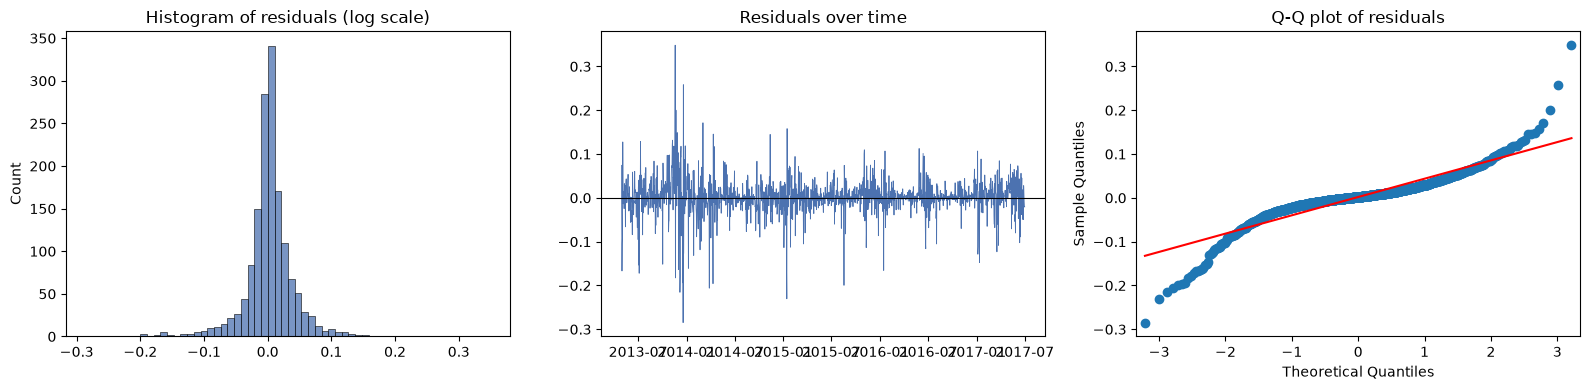

Skew of the residuals: -0.40   kurtosis: 13.07 (a normal bell gives 0 and 3)


In [13]:
# Residual diagnostics of the fitted model. The first residual is skipped because
# with d equals 1 the model has no previous day to difference against
residuals = model_validation.resid.iloc[1:]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(residuals, bins=60, ax=axes[0], color='#4c72b0')
axes[0].set_title('Histogram of residuals (log scale)')
axes[1].plot(residuals, color='#4c72b0', linewidth=0.6)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Residuals over time')
sm.qqplot(residuals, line='s', ax=axes[2])
axes[2].set_title('Q-Q plot of residuals')
plt.tight_layout()
plt.show()
print("Skew of the residuals: %.2f   kurtosis: %.2f (a normal bell gives 0 and 3)" % (residuals.skew(), residuals.kurt() + 3))

The histogram is a narrow spike centred on zero with long thin tails on both sides, not a bell: most days the model is off by less than 3 percent, and a few days it is off by 20. The time plot shows the tails are concentrated in 2013 and early 2014, when the market was small and the price could move ten percent in a day. The Q-Q plot compares the sorted residuals with what a normal distribution would give, and the dots leave the line sharply at both ends, the mark of heavy tails. The kurtosis printed under the plot, around 13 against the 3 of a normal, puts a number on it. This does not make the forecast wrong, since ARIMA is fitted by least squares like a regression, but it does mean the confidence band of the forecast, which assumes normal errors, is too narrow for the bad days.

## Evaluation (CRISP-DM 5)

The model forecasts the 30 validation days it did not see, and the forecast is compared with the real closing prices in dollars, after undoing the logarithm with the exponential. Three metrics are used: the mean absolute error, the average miss in dollars, the root mean squared error, which weighs the large misses more, and the mean absolute percentage error, the miss as a percentage of the real price, which is the number a holder cares about.

The forecast is also compared with the naive one, which says that every future day will close at the last price seen. The ACF suggested that the naive forecast is about the best available, and a model that cannot beat it has learned nothing usable.

In [14]:
# Forecast the validation stretch with its 95 percent confidence band
forecast = model_validation.get_forecast(steps=VALIDATION_DAYS)
predicted_validation = np.exp(forecast.predicted_mean)
band = np.exp(forecast.conf_int())
predicted_validation.index = price_validation.index
band.index = price_validation.index

# Naive forecast: the last known price, repeated
last_known_price = float(np.exp(log_train.iloc[-1]))
naive_validation = pd.Series(last_known_price, index=price_validation.index)

def report(name, real, predicted):
    return pd.Series({
        'MAE (USD)': mean_absolute_error(real, predicted),
        'RMSE (USD)': np.sqrt(mean_squared_error(real, predicted)),
        'MAPE (%)': float((abs(real - predicted) / real).mean() * 100),
    }, name=name)

validation_scores = pd.concat([report('ARIMA %s' % (BEST_ORDER,), price_validation, predicted_validation),
                               report('Naive (last price)', price_validation, naive_validation)], axis=1)
print("Validation stretch, %d days" % VALIDATION_DAYS)
print(validation_scores.round(2))

Validation stretch, 30 days
            ARIMA (3, 1, 3)  Naive (last price)
MAE (USD)            210.69              214.08
RMSE (USD)           246.60              249.65
MAPE (%)               8.44                8.55


On the 30 validation days the ARIMA misses by 211 dollars on average, 8.4 percent of the price, and the naive forecast by 214 dollars, 8.6 percent. The two are three dollars apart on a price of 2,500. The six parameters of the ARIMA bought a difference of one tenth of a percentage point, which on a single 30 day stretch is indistinguishable from luck. Both errors are large because July 2017 was a turbulent month, with the price falling from 2,600 to 1,930 and recovering to 2,875 within the window, and no model fitted on the past could know that.

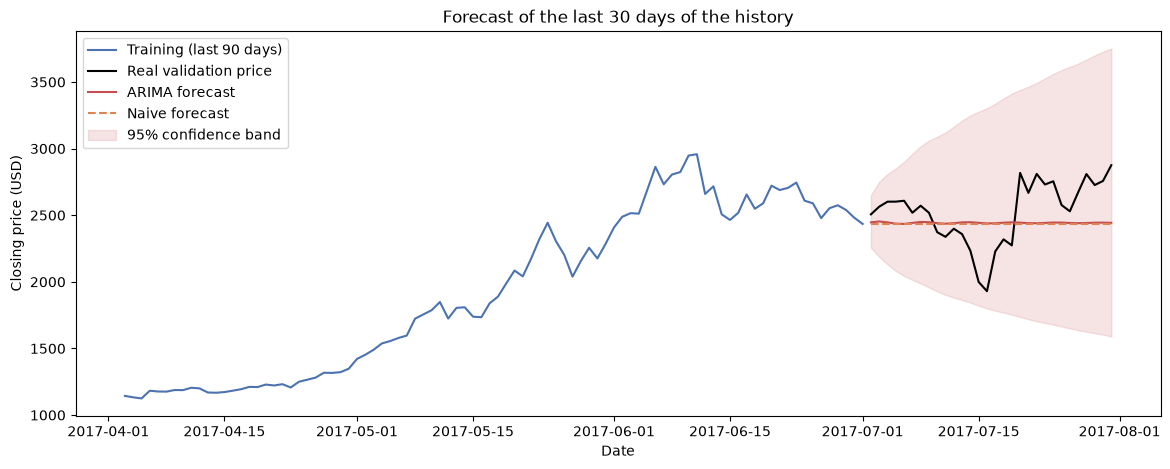

In [15]:
# Forecast against the real validation days
CONTEXT_DAYS = 90
context = bitcoin[TARGET].iloc[-(VALIDATION_DAYS + CONTEXT_DAYS):-VALIDATION_DAYS]

plt.figure(figsize=(14, 5))
plt.plot(context.index, context, color='#4c72b0', label='Training (last 90 days)')
plt.plot(price_validation.index, price_validation, color='black', label='Real validation price')
plt.plot(predicted_validation.index, predicted_validation, color='#c44e52', label='ARIMA forecast')
plt.plot(naive_validation.index, naive_validation, color='#dd8452', linestyle='--', label='Naive forecast')
plt.fill_between(band.index, band.iloc[:, 0], band.iloc[:, 1], color='#c44e52', alpha=0.15, label='95% confidence band')
plt.title('Forecast of the last 30 days of the history')
plt.xlabel('Date')
plt.ylabel('Closing price (USD)')
plt.legend()
plt.show()

The black line is what happened, the red line is the ARIMA forecast and the dashed orange line is the naive one. The two forecasts are almost the same nearly flat line at about 2,440 dollars, because with no memory in the returns the best guess for every future day is the last price plus a tiny drift. The shaded band is the 95 percent confidence band, and it fans open with the horizon, from about 400 dollars wide on the first day to more than 2,100 wide on the thirtieth, which is what the course describes as the error growing with the horizon. The real price stays inside the band, but it crosses the forecast line six times, and the drop to 1,930 in the middle of the month comes close to the lower edge. The band is honest about how little the model knows and the flat line is honest about what it knows.

In [16]:
# Refit on the whole history and forecast the seven days of the final week file
FINAL_WEEK_DAYS = len(bitcoin_week)
model_final = ARIMA(log_price, order=BEST_ORDER).fit()
forecast_week = model_final.get_forecast(steps=FINAL_WEEK_DAYS)
predicted_week = np.exp(forecast_week.predicted_mean)
predicted_week.index = bitcoin_week.index
naive_week = pd.Series(float(bitcoin[TARGET].iloc[-1]), index=bitcoin_week.index)

week_table = pd.DataFrame({'Real close': bitcoin_week[TARGET], 'ARIMA': predicted_week, 'Naive': naive_week})
week_table['ARIMA error'] = week_table['ARIMA'] - week_table['Real close']
print(week_table.round(0))
print()
week_scores = pd.concat([report('ARIMA %s' % (BEST_ORDER,), bitcoin_week[TARGET], predicted_week),
                         report('Naive (last price)', bitcoin_week[TARGET], naive_week)], axis=1)
print("Final week, %d unseen days" % FINAL_WEEK_DAYS)
print(week_scores.round(2))

            Real close   ARIMA   Naive  ARIMA error
Date                                               
2017-08-01      2718.0  2885.0  2875.0        167.0
2017-08-02      2711.0  2903.0  2875.0        193.0
2017-08-03      2805.0  2908.0  2875.0        103.0
2017-08-04      2896.0  2893.0  2875.0         -3.0
2017-08-05      3253.0  2879.0  2875.0       -374.0
2017-08-06      3214.0  2882.0  2875.0       -332.0
2017-08-07      3379.0  2898.0  2875.0       -481.0

Final week, 7 unseen days
            ARIMA (3, 1, 3)  Naive (last price)
MAE (USD)            236.10              233.24
RMSE (USD)           282.12              284.86
MAPE (%)               7.58                7.45


The final week is the real test, since neither model saw any of it and the model was refitted on the whole history up to July 31. The ARIMA forecasts a flat 2,880 to 2,910 dollars for the seven days. The real price dipped to 2,711 on August 2 and then jumped to 3,379 by August 7, a rise of 17 percent in one week that no forecast built on the past could contain. The ARIMA misses by 236 dollars on average, 7.6 percent, and the naive forecast by 233 dollars, 7.4 percent. On this week the naive forecast wins, by three dollars. Across the validation stretch and the final week the two forecasts trade places by amounts that mean nothing, which is the result the ACF announced: the daily return of bitcoin has no usable memory, and the ARIMA has nothing to add to the last price.

## Results (CRISP-DM 6: Deployment)

The model built is an ARIMA with the order chosen by AIC on the logarithm of the daily closing price, with one differencing decided by the augmented Dickey-Fuller test. On the 30 validation days it reaches a mean absolute error of 211 dollars, a root mean squared error of 247 and a mean absolute percentage error of 8.4 percent, and on the seven unseen days of August 2017 it reaches 236 dollars, 282 and 7.6 percent. The naive forecast, which repeats the last price, reaches 214 dollars and 8.6 percent on the validation days and 233 dollars and 7.4 percent on the final week. The ARIMA does not beat it in any meaningful way, and that is the honest result of this notebook.

The cause is in the data, not in the fitting. The autocorrelation of the daily return is inside the noise band at every lag that matters, so the price behaves as a random walk, where the best forecast of tomorrow is today, and the six weights of the model all have a `P>|z|` above 0.2. What the model does provide, and the naive forecast does not, is the confidence band, a range that widens with the horizon and tells the user how uncertain the number is, and on the validation stretch that band contained the real price. The residuals also show heavy tails and a spread that changed over the years, so the band is optimistic on the worst days.

The model is stored for the assistant with the recommendation that its answer to "what will bitcoin cost tomorrow" be read as "about today's price, plus or minus the band", and never as a trading signal. It was fitted on data ending in July 2017, so it knows nothing of the market after that, and any use beyond a few days ahead is extrapolation the band already flags as nearly useless. The fitted model, its order and its last date are saved below so the REST API can forecast without refitting.

In [17]:
bundle = {
    'model': model_final,
    'order': tuple(int(v) for v in BEST_ORDER),
    'last_date': str(bitcoin.index.max().date()),
    'target': TARGET,
    'target_transform': 'log',
}
MODEL_PATH = os.path.join(MODELS_DIR, 'bitcoin_price_regression.joblib')
joblib.dump(bundle, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to ../models/bitcoin_price_regression.joblib


In [18]:
# Reload and forecast the next seven days by hand, with the 95 percent band in dollars
loaded = joblib.load(MODEL_PATH)
FORECAST_DAYS = 7
reloaded_forecast = loaded['model'].get_forecast(steps=FORECAST_DAYS)
hand_forecast = pd.DataFrame({
    'Forecast (USD)': np.exp(reloaded_forecast.predicted_mean),
    'Lower 95%': np.exp(reloaded_forecast.conf_int().iloc[:, 0]),
    'Upper 95%': np.exp(reloaded_forecast.conf_int().iloc[:, 1]),
})
hand_forecast.index = pd.date_range(pd.Timestamp(loaded['last_date']) + pd.Timedelta(days=1), periods=FORECAST_DAYS)
print("Forecast for the seven days after", loaded['last_date'])
print(hand_forecast.round(0))

Forecast for the seven days after 2017-07-31
            Forecast (USD)  Lower 95%  Upper 95%
2017-08-01          2885.0     2656.0     3134.0
2017-08-02          2903.0     2584.0     3262.0
2017-08-03          2908.0     2524.0     3350.0
2017-08-04          2893.0     2463.0     3399.0
2017-08-05          2879.0     2407.0     3443.0
2017-08-06          2882.0     2368.0     3507.0
2017-08-07          2898.0     2342.0     3586.0


The reloaded model gives the same seven day forecast as the evaluation, a nearly flat line near 2,900 dollars with a band that opens from roughly plus or minus 240 dollars on the first day to plus or minus 620 on the seventh. This is the call the REST API makes: load the bundle, ask for the number of days, undo the logarithm and return the forecast with its band.